In [1]:
# What are districts made of - US Census Blocks - need to find & download them for california
# The starting plans in questions
# Markov chain
# Convergence: do a sliding window & check mean + interquartile range for compactness & voting statistics
# Voting statistics - D v R (using 2022 & 2024 congressional elections)
# Compactness score - Cut edges or spanning tree


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import gerrychain
from gerrychain import Graph, Partition, MarkovChain, updaters
from gerrychain.proposals import ReCom
from gerrychain.constraints import within_percent_of_ideal_population
import maup
import geopandas as gpd


/rhome/drfj2024/.local/lib/python3.13/site-packages/maup/smart_repair.py:34: Pandas4Warning: The 'mode.chained_assignment' option is deprecated. It has had no effect since pandas 3.0, which removed the SettingWithCopyWarning it controlled. Chained assignment now emits a ChainedAssignmentError warning instead; use warnings.filterwarnings with category=ChainedAssignmentError to silence or escalate it. This option will be removed in pandas 4.0.
  pandas.options.mode.chained_assignment = None


In [3]:
# Load all shapefiles
# CA Census Blocks
ca_blck = gpd.read_file(filename="tl_2020_06_tabblock20/tl_2020_06_tabblock20.shp")
# Prop 50 District Plan
ca_prop50 = gpd.read_file("California Prop 50/AB_604_-_California_Congressional_Districts_2027-2032_as_enacted_by_Proposition_50.shp")
# 2020 District Plan
ca_2020 = gpd.read_file("California_US_Congressional_Districts_Map_2020/California_US_Congressional_Districts_Map_2020.shp")

In [ ]:
fig, axs = plt.subplots(nrows=2, ncols=2, figsize=(10, 10))
ca_blck.plot(ax=axs[0,0])
ca_prop50.plot(ax=axs[0,1])
ca_2020.plot(ax=axs[1, 1])


In [18]:
# Load voting data from 2022 midterm election
prec_2022 = gpd.read_file("srprec_state_g22_v01_shp/srprec_state_g22_v01_shp.shp")
# prec_2022 = prec_2022.to_crs(ca_prop50.crs)
votes_prec_2022 = pd.read_csv("state_g22_sov_data_by_g22_srprec.csv")
prec_to_blk_2022 = pd.read_csv("state_g22_sr_blk_map.csv", dtype={"BLOCK_KEY": "str"})

# Aggregate democratic votes as sometimes there were 2 candidates
votes_prec_2022["CNGDEM"] = votes_prec_2022["CNGDEM01"] + votes_prec_2022["CNGDEM02"]

# Ensure SRPREC column has the same dtype in both DataFrames
votes_prec_2022["SRPREC"] = votes_prec_2022["SRPREC"].astype(str)
prec_to_blk_2022["SRPREC"] = prec_to_blk_2022["SRPREC"].astype(str)

# Run normalization on conversion factors to avoid pulling votes out of thin air
prec_to_blk_2022['PCTSRPREC'] = prec_to_blk_2022.groupby('SRPREC')['PCTSRPREC'].transform(lambda x: x / x.sum())

# Merge precinct voting data with precinct to block conversion data
votes_blk_2022 = pd.merge(left=votes_prec_2022, right=prec_to_blk_2022, on="SRPREC", how="inner")

# Distribute voting data across census blocks based on precinct to block conversion
# Method derived from https://statewidedatabase.org/faq.html#merge_registration
votes_blk_2022['CNGDEM2022'] = votes_blk_2022['CNGDEM'] * votes_blk_2022['PCTSRPREC'].astype("float64") 
votes_blk_2022['CNGREP2022'] = votes_blk_2022['CNGREP01'] * votes_blk_2022['PCTSRPREC'].astype("float64")

# Sum the voting data by census block
votes_blk_2022 = votes_blk_2022.groupby(by='BLOCK_KEY').sum().reset_index()

# Drop unnecessary data
votes_blk_2022 = votes_blk_2022[["BLOCK_KEY", "CNGDEM2022", "CNGREP2022"]]
votes_blk_2022["TOT2022"] = votes_blk_2022["CNGDEM2022"] + votes_blk_2022["CNGREP2022"]
votes_blk_2022["DEM_FRAC2022"] = votes_blk_2022["CNGDEM2022"] / votes_blk_2022["TOT2022"]

# Now that we have voting data by census block, we can merge that data into our census block geodataframe, then analyze the different plans
ca_blck_w_votes2022 = pd.merge(ca_blck, right=votes_blk_2022, left_on="GEOID20", right_on="BLOCK_KEY", how="left")

# Verification of votes
og_tot = votes_prec_2022["CNGDEM01"].sum() + votes_prec_2022["CNGDEM02"].sum() + votes_prec_2022["CNGREP01"].sum()
now_tot = ca_blck_w_votes2022["TOT2022"].sum()
print(now_tot / og_tot)





0.9999668962607255


In [11]:
ca_blck_w_votes2022 = ca_blck_w_votes2022[["GEOID20", "POP20", "geometry", "CNGDEM2022", "CNGREP2022", "TOT2022"]]

In [12]:
ca_blck_w_votes2022.columns

Index(['GEOID20', 'POP20', 'geometry', 'CNGDEM2022', 'CNGREP2022', 'TOT2022'],
      dtype='str')

In [25]:
# Load voting data from 2024 midterm election
prec_2024 = gpd.read_file("2024 Vote Data/srprec_state_g24_v01_shp/srprec_state_g24_v01_shp.shp", dtype={"SRPREC": "str"})
votes_prec_2024 = pd.read_csv("2024 Vote Data/state_g24_sov_data_by_g24_srprec.csv", dtype={"SRPREC": "str", "SRPREC_KEY": "str"})
prec_to_blk_2024 = pd.read_csv("2024 Vote Data/state_g24_sr_blk_map.csv", dtype={"BLOCK_KEY": "str", "SRPREC": "str", "SRPREC_KEY": "str"})

# Aggregate democratic votes as sometimes there were 2 candidates
votes_prec_2024["CNGDEM"] = pd.to_numeric(votes_prec_2024["CNGDEM01"], errors="coerce").fillna(0).astype("int64") + pd.to_numeric(votes_prec_2024["CNGDEM02"], errors="coerce").fillna(0).astype("int64")
# For this one, do same for REP
votes_prec_2024["CNGREP"] = pd.to_numeric(votes_prec_2024["CNGREP01"], errors="coerce").fillna(0).astype("int64") + pd.to_numeric(votes_prec_2024["CNGREP02"], errors="coerce").fillna(0).astype("int64")

# Run normalization on conversion factors to avoid pulling votes out of thin air
prec_to_blk_2024['PCTSRPREC'] = prec_to_blk_2024.groupby('SRPREC')['PCTSRPREC'].transform(lambda x: x / x.sum())

# Merge precinct voting data with precinct to block conversion data
votes_blk_2024 = pd.merge(left=votes_prec_2024, right=prec_to_blk_2024, on="SRPREC", how="inner")

# Distribute voting data across census blocks based on precinct to block conversion
# Method derived from https://statewidedatabase.org/faq.html#merge_registration
votes_blk_2024['CNGDEM2024'] = votes_blk_2024['CNGDEM'] * votes_blk_2024['PCTSRPREC'].astype("float64") 
votes_blk_2024['CNGREP2024'] = votes_blk_2024['CNGREP'] * votes_blk_2024['PCTSRPREC'].astype("float64")

# Sum the voting data by census block
votes_blk_2024 = votes_blk_2024.groupby(by='BLOCK_KEY').sum().reset_index()

# Drop unnecessary data
votes_blk_2024 = votes_blk_2024[["BLOCK_KEY", "CNGDEM2024", "CNGREP2024"]]
votes_blk_2024["TOT2024"] = votes_blk_2024["CNGDEM2024"] + votes_blk_2024["CNGREP2024"]
votes_blk_2024["DEM_FRAC2024"] = votes_blk_2024["CNGDEM2024"] / votes_blk_2024["TOT2024"]

# Now that we have voting data by census block, we can merge that data into our census block geodataframe, then analyze the different plans
ca_blck_w_votesAll = pd.merge(ca_blck_w_votes2022, right=votes_blk_2024, left_on="GEOID20", right_on="BLOCK_KEY", how="left")

# Verification of votes
og_tot = pd.to_numeric(votes_prec_2024["CNGDEM01"], errors="coerce").fillna(0).astype("int64").sum() + pd.to_numeric(votes_prec_2024["CNGDEM02"], errors="coerce").fillna(0).astype("int64").sum() + pd.to_numeric(votes_prec_2024["CNGREP01"], errors="coerce").fillna(0).astype("int64").sum() + pd.to_numeric(votes_prec_2024["CNGREP02"], errors="coerce").fillna(0).astype("int64").sum()
now_tot = ca_blck_w_votesAll["TOT2024"].sum()
print(now_tot / og_tot)





/rhome/drfj2024/.local/lib/python3.13/site-packages/pyogrio/raw.py:200: RuntimeWarning: driver ESRI Shapefile does not support open option DTYPE
  return ogr_read(
/rhome/drfj2024/.local/lib/python3.13/site-packages/pyogrio/raw.py:200: RuntimeWarning: 2024 Vote Data/srprec_state_g24_v01_shp/srprec_state_g24_v01_shp.shp contains polygon(s) with rings with invalid winding order. Autocorrecting them, but that shapefile should be corrected using ogr2ogr for example.
  return ogr_read(


0.9999501325405359


In [28]:
ca_blck_w_votesAll = ca_blck_w_votesAll[["GEOID20", "POP20", "geometry", "CNGDEM2022", "CNGREP2022", "TOT2022", "CNGDEM2024", "CNGREP2024", "TOT2024"]]

In [31]:
# We can now analyze the 2020 and Prop 50 plans using these election results
# First, check and adjust the crs
print(ca_blck_w_votesAll.crs)
print(ca_2020.crs)
print(ca_prop50.crs)
ca_blck_w_votes_adj = ca_blck_w_votesAll.to_crs(ca_2020.crs)
print(ca_blck_w_votes_adj.crs)

EPSG:4269
EPSG:3857
EPSG:3857
EPSG:3857


In [32]:
# Create assignments
blck_to_dist_2020 = maup.assign(ca_blck_w_votes_adj.geometry, ca_2020.geometry)
blck_to_dist_prop50 = maup.assign(ca_blck_w_votes_adj.geometry, ca_prop50.geometry)

/rhome/drfj2024/.local/lib/python3.13/site-packages/geopandas/geoseries.py:788: Pandas4Warning: The inplace keyword in GeoSeries.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  val = getattr(super(), mtd)(*args, **kwargs)
/rhome/drfj2024/.local/lib/python3.13/site-packages/geopandas/geoseries.py:788: Pandas4Warning: The inplace keyword in GeoSeries.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  val = getattr(super(), mtd)(*args, **kwargs)


In [33]:
plan_votes = ca_blck_w_votes_adj.copy()
plan_votes["prop50"] = blck_to_dist_prop50 + 1
plan_votes["2020"] = blck_to_dist_2020 + 1


<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

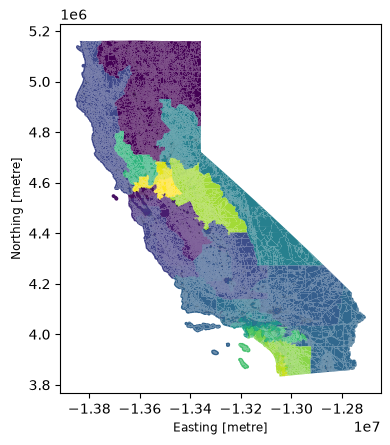

In [34]:
plan_votes.plot(column = "2020")

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

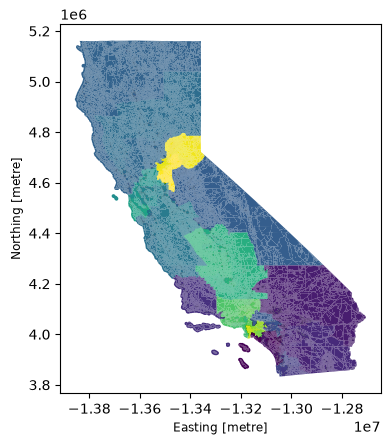

In [35]:
plan_votes.plot(column="prop50")

In [36]:
plan_votes_2020 = plan_votes.dissolve(by="2020", aggfunc="sum")
plan_votes_prop50 = plan_votes.dissolve(by="prop50", aggfunc="sum")

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

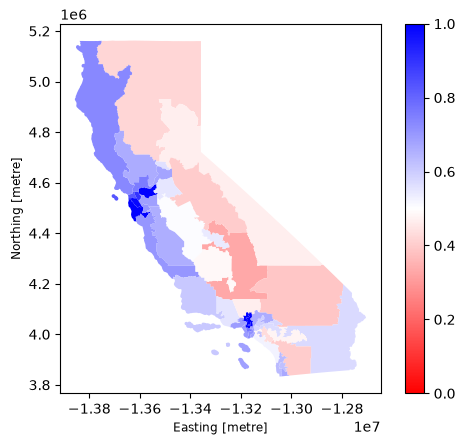

In [38]:
plan_votes_2020["DEM_FRAC2022"] = plan_votes_2020["CNGDEM2022"] / plan_votes_2020["TOT2022"]
plan_votes_2020.plot(column="DEM_FRAC2022", cmap="bwr_r", legend=True, missing_kwds={"color": "black"}, vmin=0, vmax=1)

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

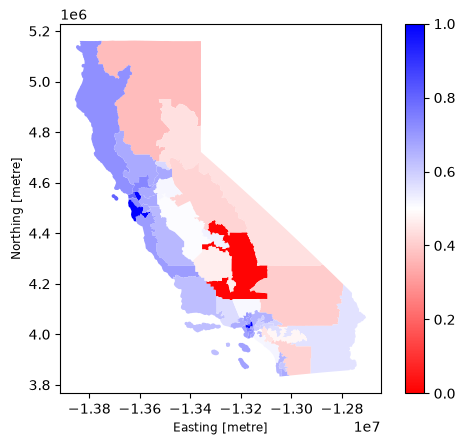

In [39]:
plan_votes_2020["DEM_FRAC2024"] = plan_votes_2020["CNGDEM2024"] / plan_votes_2020["TOT2024"]
plan_votes_2020.plot(column="DEM_FRAC2024", cmap="bwr_r", legend=True, missing_kwds={"color": "black"}, vmin=0, vmax=1)

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

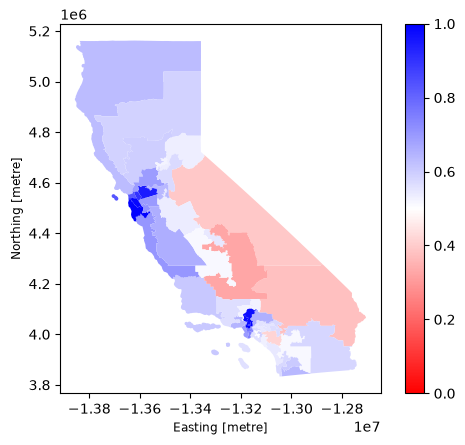

In [40]:
plan_votes_prop50["DEM_FRAC2022"] = plan_votes_prop50["CNGDEM2022"] / plan_votes_prop50["TOT2022"]
plan_votes_prop50.plot(column="DEM_FRAC2022", cmap="bwr_r", legend=True, missing_kwds={"color": "black"}, vmin=0, vmax=1)

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

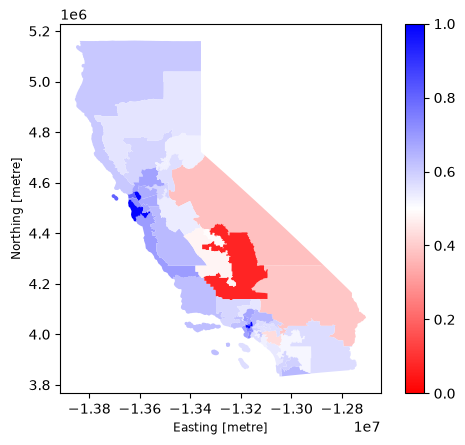

In [41]:
plan_votes_prop50["DEM_FRAC2024"] = plan_votes_prop50["CNGDEM2024"] / plan_votes_prop50["TOT2024"]
plan_votes_prop50.plot(column="DEM_FRAC2024", cmap="bwr_r", legend=True, missing_kwds={"color": "black"}, vmin=0, vmax=1)

In [ ]:
ideal_pop = sum(ca_blck_w_votes_adj['POP20']) / len(plan_votes_prop50)
ca_blck_w_votes_adj_filled = ca_blck_w_votes_adj.copy()
ca_blck_w_votes_adj_filled["CNGDEM2022"] = ca_blck_w_votes_adj_filled["CNGDEM2022"].fillna(0)
ca_blck_w_votes_adj_filled["CNGREP2022"] = ca_blck_w_votes_adj_filled["CNGREP2022"].fillna(0)
ca_blck_w_votes_adj_filled["CNGDEM2024"] = ca_blck_w_votes_adj_filled["CNGDEM2024"].fillna(0)
ca_blck_w_votes_adj_filled["CNGREP2024"] = ca_blck_w_votes_adj_filled["CNGREP2024"].fillna(0)
chain_graph = Graph.from_geodataframe(ca_blck_w_votes_adj_filled)

In [ ]:
w_chain = MarkovChain(total_steps=100000, rng = 2026)
chain_updaters = {
    "population": updaters.Tally("POP20", alias="population"),
    "DemVotes2022": updaters.Tally("CNGDEM2022", alias = "DemVotes2022"),
    "RepVotes2022": updaters.Tally("CNGREP2022", alias = "RepVotes2022"),
    "DemVotes2024": updaters.Tally("CNGDEM2024", alias = "DemVotes2024"),
    "RepVotes2024": updaters.Tally("CNGREP2024", alias = "RepVotes2024"),
    "cut_edges": updaters.cut_edges
}

In [ ]:
w_chain.initial_partition = Partition.from_random_assignment(
    graph=chain_graph, 
    n_parts=52, 
    epsilon=0.01,
    pop_col="POP20", 
    updaters = chain_updaters,
    rng=2026 
) 

In [ ]:
w_chain.proposal_fn = ReCom.district_pairs_mst(
    pop_col = "POP20", # The name of our total population attribute in the graph
    pop_target = ideal_pop, # the ideal population for each district, which we calculated above
    epsilon = 0.01 # the population tolerance, or how much the population of each district can differ from the ideal population
)

In [ ]:
for i, partition in enumerate(w_chain):
    for district_name in partition["population"]:
        dem_votes = partition["DemVotes2022"][district_name]
        rep_votes = partition["RepVotes2022"][district_name]
        dem_votes2 = partition["DemVotes2024"][district_name]
        rep_votes2 = partition["RepVotes2024"][district_name]
        tot_votes = dem_votes + rep_votes
        dem_frac = dem_votes / tot_votes
        dem_majority = dem_frac >= 0.5
        
        tot_votes2 = dem_votes2 + rep_votes2
        dem_frac2 = dem_votes2 / tot_votes2
        dem_majority2 = dem_frac2 >= 0.5
        chain_data = pd.DataFrame({
            "step": i,
            "district_name": district_name,
            "population": partition["population"][district_name],
            "dem_votes2022": dem_votes,
            "rep_votes2022": rep_votes,
            "dem_votes2024": dem_votes2,
            "rep_votes2024": rep_votes2,
            "dem_frac": dem_frac,
            "dem_frac2": dem_frac2,
            "dem_majority": dem_majority,
            "dem_majority2": dem_majority2,
            "n_cut_edges": len(partition["cut_edges"])
        }, index=[0])
        chain_data.to_json('markov_chain_output_RANDOM.json', orient="records", lines=True, mode='a')